# Agrupamiento de condiciones de operación
**Diego Salinas Laguna · AI4I 2020**

Se buscan perfiles de funcionamiento con K-means. Las entradas son ambas temperaturas, velocidad, torque y desgaste. Las etiquetas de falla solo se usan para describir grupos después del ajuste.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/agrupamiento.py').is_file())
sys.path.insert(0, str(root/'src'))
from agrupamiento import ejecutar

metrics = ejecutar(root)
display(pd.read_csv(root/'results/comparacion_agrupamiento.csv').round(3))

,k,silueta_validacion
0,2,0.254
1,3,0.261
2,4,0.240
3,5,0.224
4,6,0.212


Probamos entre dos y seis grupos y elegimos el valor con mayor silueta en validación. La escala y K-means se ajustan con entrenamiento. La prueba se usa para revisar la separación al final.

,grupo,registros,fallas,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],porcentaje_fallas
0,1,4019,87,298.26,308.74,1474.50,43.24,104.67,2.16
1,2,2087,46,300.16,310.13,1794.16,26.68,109.06,2.20
2,3,3894,206,301.72,311.25,1468.24,43.77,110.75,5.29


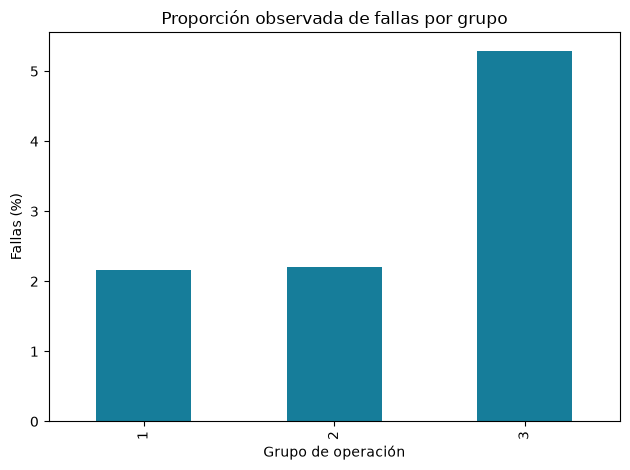

Grupos: 3. Silueta de prueba: 0.268


In [2]:
profiles = pd.read_csv(root/'results/perfiles_agrupamiento.csv')
display(profiles.round(2))
ax = profiles.plot.bar(x='grupo', y='porcentaje_fallas', legend=False, color='#167D9A')
ax.set(title='Proporción observada de fallas por grupo', xlabel='Grupo de operación', ylabel='Fallas (%)')
plt.tight_layout()
plt.show()
print(f"Grupos: {metrics['k_elegido']}. Silueta de prueba: {metrics['silueta_prueba']:.3f}")

Se eligieron tres grupos. La silueta de prueba de 0.268 indica que los perfiles tienen separación limitada y pueden superponerse. Las proporciones de falla ayudan a describir los grupos, pero el modelo no se entrenó para predecir una falla. Estos resultados corresponden a datos sintéticos.